# Chapter 6 · PCA

*Book 1 · Linear Algebra · Shelf I*

**Builds on:** [Chapter 5](05-eigenvalues-and-svd.ipynb) (the SVD and low-rank approximation)
and variance from book 4.
**You will:** compute principal components from the SVD, read how much variance each explains,
draw a 64-dimensional dataset in two dimensions, and rebuild its images from a handful of numbers.

**Principal component analysis** finds the directions in which a dataset varies most. It is the
SVD of the centred data matrix, nothing more -- and it is the first thing to try when a table has
too many columns to look at.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import load_digits
from sklearn.decomposition import PCA

from ds_toolbox import viz

viz.use_style()

## The data: handwritten digits

1 797 images of digits, each 8 x 8 grey pixels -- 64 numbers per image. The dataset ships with
scikit-learn, so nothing is downloaded.

(1797, 64)


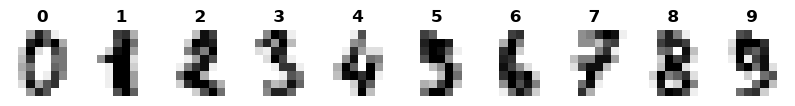

In [2]:
digits = load_digits()
X, y = digits.data, digits.target
print(X.shape)
fig, axes = plt.subplots(1, 10, figsize=(10, 1.4))
for ax, img, label in zip(axes, digits.images, y, strict=False):
    ax.imshow(img, cmap="gray_r")
    ax.set_title(label)
    ax.axis("off")

## PCA is the SVD of the centred data

Subtract each column's mean, then take the SVD $X_c = U\Sigma V^\top$. The rows of $V^\top$ are the
principal directions; $\sigma_i^2 / (n - 1)$ is the variance along direction $i$.

In [3]:
Xc = X - X.mean(axis=0)
U, s, Vt = np.linalg.svd(Xc, full_matrices=False)
explained = s ** 2 / (s ** 2).sum()
lib = PCA().fit(X)
print("by hand, first 5:", explained[:5].round(4))
print("sklearn, first 5:", lib.explained_variance_ratio_[:5].round(4))

by hand, first 5: [0.1489 0.1362 0.1179 0.0841 0.0578]
sklearn, first 5: [0.1489 0.1362 0.1179 0.0841 0.0578]


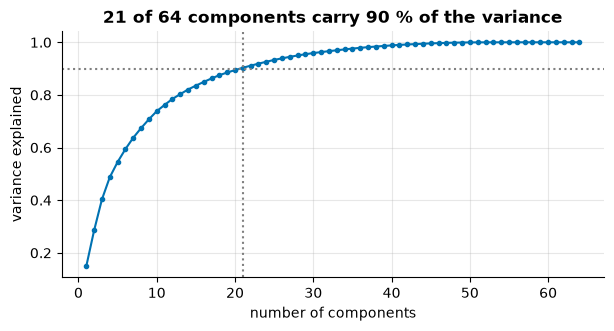

In [4]:
cum = np.cumsum(explained)
k90 = int(np.searchsorted(cum, 0.90) + 1)
plt.figure(figsize=(7, 3.2))
plt.plot(np.arange(1, 65), cum, marker=".")
plt.axhline(0.9, color="0.5", ls=":")
plt.axvline(k90, color="0.5", ls=":")
plt.xlabel("number of components")
plt.ylabel("variance explained")
plt.title(f"{k90} of 64 components carry 90 % of the variance");

## Sixty-four dimensions, drawn in two

Project every image onto the first two directions. Nothing about the labels went into PCA, yet
several digits form their own clouds -- the directions of largest variance happen to separate them.

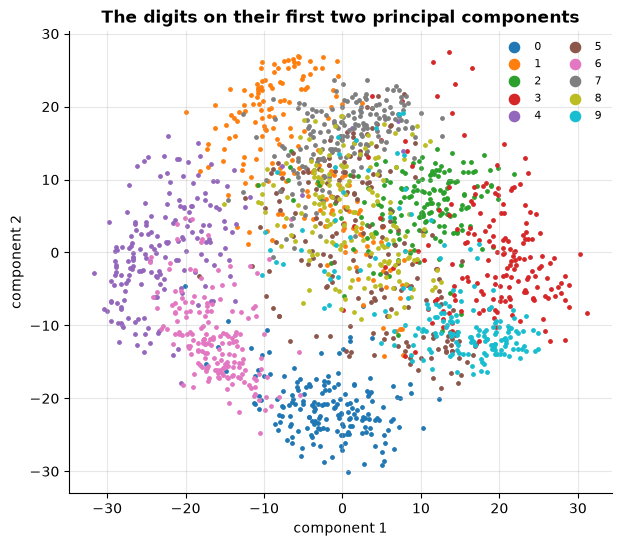

In [5]:
Z = Xc @ Vt[:2].T
plt.figure(figsize=(7, 6))
for d in range(10):
    plt.scatter(*Z[y == d].T, s=6, label=str(d), color=plt.cm.tab10(d))
plt.legend(markerscale=3, ncol=2, fontsize=8)
plt.xlabel("component 1")
plt.ylabel("component 2")
plt.title("The digits on their first two principal components");

## What the components look like

Each principal direction is itself a 64-pixel image: a pattern of light and dark that the digits
vary along.

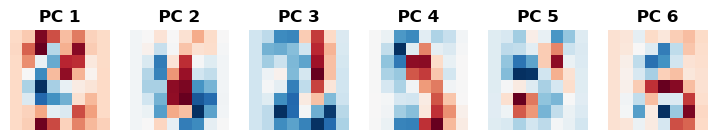

In [6]:
fig, axes = plt.subplots(1, 6, figsize=(9, 1.8))
for i, ax in enumerate(axes):
    ax.imshow(Vt[i].reshape(8, 8), cmap="RdBu_r")
    ax.set_title(f"PC {i + 1}")
    ax.axis("off")

## Rebuilding from fewer numbers

Keep $k$ coordinates per image, then map back: chapter 5's low-rank approximation, applied to a
dataset. A few components already give a recognisable digit.

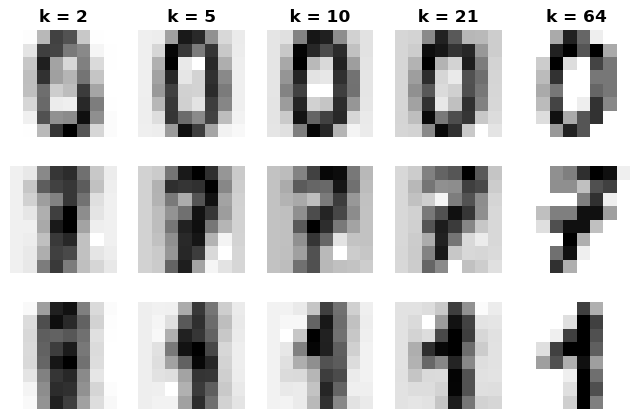

In [7]:
ks = [2, 5, 10, k90, 64]
fig, axes = plt.subplots(3, len(ks), figsize=(8, 5))
for row, idx in enumerate([0, 7, 42]):
    for col, k in enumerate(ks):
        rebuilt = X.mean(axis=0) + (Xc[idx] @ Vt[:k].T) @ Vt[:k]
        axes[row, col].imshow(rebuilt.reshape(8, 8), cmap="gray_r")
        axes[row, col].axis("off")
        if row == 0:
            axes[row, col].set_title(f"k = {k}")

## What PCA does not do

PCA finds directions of *variance*, not of meaning. If a column is measured in large units it
dominates; standardise first when the units differ. And it is linear: structure that bends -- a
spiral, a ring -- needs other methods (book 22).

## What to remember

- PCA is the SVD of the centred data; the singular values give the variance per component.
- Read the cumulative explained variance to choose how many components to keep.
- Standardise when the columns have different units.

## Exercises

1. Multiply one pixel column by 100 and rerun. What happens to the first component?
2. Classify the digits with a nearest-neighbour rule on 10 components and on all 64. Compare.
3. How many components carry 99 % of the variance?

**Next:** [The challenge · photo-compress](challenge/photo-compress.ipynb)